# Introduction 
This notebook performs an exploratory data analysis and feature engineering step using the cleaned lung cancer dataset from Assignment 2. The main goal here is to get a clearer picture of how the demographic, clinical, treatment, lab, and comorbidity variables are distributed and how they relate to one another, so we can spot patterns that might help predict short-term versus long-term survival. The analysis also includes correlation analysis, feature engineering, feature selection considerations, and principal component analysis (PCA).


# Load the dataset


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.feature_selection import VarianceThreshold

df = pd.read_csv("../data/lung_cancer_cleaned.csv")

print("Dataset shape:", df.shape)

display(df.head())


Dataset shape: (23658, 48)


,Age,Tumor_Size_mm,Performance_Status,Blood_Pressure_Systolic,Blood_Pressure_Diastolic,Blood_Pressure_Pulse,Hemoglobin_Level,White_Blood_Cell_Count,Platelet_Count,Albumin_Level,...,Insurance_Type_Private,Family_History_Yes,Comorbidity_Diabetes_Yes,Comorbidity_Hypertension_Yes,Comorbidity_Heart_Disease_Yes,Comorbidity_Chronic_Lung_Disease_Yes,Comorbidity_Kidney_Disease_Yes,Comorbidity_Autoimmune_Disease_Yes,Comorbidity_Other_Yes,Survival_Group
0,51,30.312823,0,163,78,60,15.610565,3.543686,250.887930,3.731595,...,0,0,0,1,1,1,0,0,0,Short-Term
1,47,15.668398,3,178,64,93,16.968066,4.137507,210.907856,4.707746,...,0,1,0,1,1,1,1,1,0,Long-Term
2,71,58.319399,3,96,89,69,13.108920,5.285139,192.435582,4.540101,...,0,0,1,0,1,1,0,0,0,Long-Term
3,67,67.116956,1,130,85,78,14.898905,7.274861,411.558815,4.095703,...,0,1,1,0,1,1,0,1,1,Long-Term
4,69,95.779354,0,167,100,75,15.952222,7.258468,278.649120,3.567760,...,0,1,1,0,1,1,1,0,1,Long-Term


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 23658 entries, 0 to 23657
Data columns (total 48 columns):
 #   Column                                Non-Null Count  Dtype  
---  ------                                --------------  -----  
 0   Age                                   23658 non-null  int64  
 1   Tumor_Size_mm                         23658 non-null  float64
 2   Performance_Status                    23658 non-null  int64  
 3   Blood_Pressure_Systolic               23658 non-null  int64  
 4   Blood_Pressure_Diastolic              23658 non-null  int64  
 5   Blood_Pressure_Pulse                  23658 non-null  int64  
 6   Hemoglobin_Level                      23658 non-null  float64
 7   White_Blood_Cell_Count                23658 non-null  float64
 8   Platelet_Count                        23658 non-null  float64
 9   Albumin_Level                         23658 non-null  float64
 10  Alkaline_Phosphatase_Level            23658 non-null  float64
 11  Alanine_Aminotr

# Dataset Overview

In [6]:
#Shape 
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 23658
Number of columns: 48


In [7]:
#Coulumn names
print(df.columns.tolist())

['Age', 'Tumor_Size_mm', 'Performance_Status', 'Blood_Pressure_Systolic', 'Blood_Pressure_Diastolic', 'Blood_Pressure_Pulse', 'Hemoglobin_Level', 'White_Blood_Cell_Count', 'Platelet_Count', 'Albumin_Level', 'Alkaline_Phosphatase_Level', 'Alanine_Aminotransferase_Level', 'Aspartate_Aminotransferase_Level', 'Creatinine_Level', 'LDH_Level', 'Calcium_Level', 'Phosphorus_Level', 'Glucose_Level', 'Potassium_Level', 'Sodium_Level', 'Smoking_Pack_Years', 'Gender_Male', 'Smoking_History_Former Smoker', 'Smoking_History_Never Smoked', 'Tumor_Location_Middle Lobe', 'Tumor_Location_Upper Lobe', 'Stage_Stage II', 'Stage_Stage III', 'Stage_Stage IV', 'Treatment_Radiation Therapy', 'Treatment_Surgery', 'Treatment_Targeted Therapy', 'Ethnicity_Asian', 'Ethnicity_Caucasian', 'Ethnicity_Hispanic', 'Ethnicity_Other', 'Insurance_Type_Medicare', 'Insurance_Type_Other', 'Insurance_Type_Private', 'Family_History_Yes', 'Comorbidity_Diabetes_Yes', 'Comorbidity_Hypertension_Yes', 'Comorbidity_Heart_Disease_Yes'

In [8]:
#Target distribution
print(df["Survival_Group"].value_counts())

Survival_Group
Long-Term     11948
Short-Term    11710
Name: count, dtype: int64


In [9]:
#Calculate percentages
target_percent = (
    df["Survival_Group"]
    .value_counts(normalize=True)
    .mul(100)
)

print(target_percent)

Survival_Group
Long-Term     50.503001
Short-Term    49.496999
Name: proportion, dtype: float64


# Three Business / Healthcare Questions

Q1: How are demographic and clinical characteristics distributed across Short-Term and Long-Term survival groups?

Q2: Which clinical, laboratory, treatment, and comorbidity variables show the strongest relationships with survival group?

Q3: Can feature engineering and dimensionality reduction reveal useful patterns that are not apparent from individual predictors?

# Descriptive Statistics

In [10]:
#Numerical variables
numeric_columns = df.select_dtypes(include=np.number).columns

descriptive_stats = df[numeric_columns].describe().T

descriptive_stats["Variance"] = df[numeric_columns].var()
descriptive_stats["IQR"] = (
    descriptive_stats["75%"] -
    descriptive_stats["25%"]
)

descriptive_stats["Skewness"] = df[numeric_columns].skew()
descriptive_stats["Kurtosis"] = df[numeric_columns].kurtosis()

display(descriptive_stats)

,count,mean,std,min,25%,50%,75%,max,Variance,IQR,Skewness,Kurtosis
Age,23658.0,54.439344,14.396386,30.000000,42.000000,54.000000,67.000000,79.000000,207.255927,25.000000,0.017856,-1.190179
Tumor_Size_mm,23658.0,55.383736,26.004354,10.004279,32.972797,55.296297,78.190014,99.990554,676.226434,45.217218,-0.015195,-1.207750
Performance_Status,23658.0,1.999915,1.413675,0.000000,1.000000,2.000000,3.000000,4.000000,1.998478,2.000000,0.004459,-1.297332
Blood_Pressure_Systolic,23658.0,134.462381,26.020492,90.000000,112.000000,134.000000,157.000000,179.000000,677.066028,45.000000,0.000175,-1.204877
Blood_Pressure_Diastolic,23658.0,84.475780,14.409826,60.000000,72.000000,85.000000,97.000000,109.000000,207.643092,25.000000,-0.000857,-1.199596
Blood_Pressure_Pulse,23658.0,79.585299,11.546690,60.000000,70.000000,80.000000,90.000000,99.000000,133.326050,20.000000,-0.012206,-1.196031
Hemoglobin_Level,23658.0,14.000137,2.301411,10.000070,11.990625,13.983383,15.999260,17.999957,5.296491,4.008635,0.009319,-1.201174
White_Blood_Cell_Count,23658.0,6.735637,1.879292,3.501213,5.108723,6.729774,8.353701,9.999535,3.531738,3.244978,0.007057,-1.197849
Platelet_Count,23658.0,299.867482,86.897568,150.017892,224.884576,299.933443,375.437029,449.974734,7551.187343,150.552453,-0.001296,-1.209296
Albumin_Level,23658.0,3.998981,0.576931,3.000080,3.504579,3.999931,4.499102,4.999968,0.332850,0.994523,-0.000317,-1.195214


In [11]:
#Median
median_values = df[numeric_columns].median()

display(median_values)

Age                                      54.000000
Tumor_Size_mm                            55.296297
Performance_Status                        2.000000
Blood_Pressure_Systolic                 134.000000
Blood_Pressure_Diastolic                 85.000000
Blood_Pressure_Pulse                     80.000000
Hemoglobin_Level                         13.983383
White_Blood_Cell_Count                    6.729774
Platelet_Count                          299.933443
Albumin_Level                             3.999931
Alkaline_Phosphatase_Level               75.089745
Alanine_Aminotransferase_Level           22.547943
Aspartate_Aminotransferase_Level         30.271772
Creatinine_Level                          1.001183
LDH_Level                               174.390634
Calcium_Level                             9.259304
Phosphorus_Level                          3.730837
Glucose_Level                           109.949488
Potassium_Level                           4.242236
Sodium_Level                   

In [12]:
#Mode
mode_values = df[numeric_columns].mode().iloc[0]

display(mode_values)

Age                                      46.000000
Tumor_Size_mm                            10.004279
Performance_Status                        2.000000
Blood_Pressure_Systolic                  90.000000
Blood_Pressure_Diastolic                 64.000000
Blood_Pressure_Pulse                     62.000000
Hemoglobin_Level                         10.000070
White_Blood_Cell_Count                    3.501213
Platelet_Count                          150.017892
Albumin_Level                             3.000080
Alkaline_Phosphatase_Level               30.007235
Alanine_Aminotransferase_Level            5.001090
Aspartate_Aminotransferase_Level         10.000860
Creatinine_Level                          0.500001
LDH_Level                               100.002721
Calcium_Level                             8.000018
Phosphorus_Level                          2.500069
Glucose_Level                            70.000420
Potassium_Level                           3.500034
Sodium_Level                   

In [13]:
#Range
range_values = (
    df[numeric_columns].max()
    - df[numeric_columns].min()
)

display(range_values)

Age                                      49.000000
Tumor_Size_mm                            89.986275
Performance_Status                        4.000000
Blood_Pressure_Systolic                  89.000000
Blood_Pressure_Diastolic                 49.000000
Blood_Pressure_Pulse                     39.000000
Hemoglobin_Level                          7.999887
White_Blood_Cell_Count                    6.498323
Platelet_Count                          299.956842
Albumin_Level                             1.999888
Alkaline_Phosphatase_Level               89.987470
Alanine_Aminotransferase_Level           34.998453
Aspartate_Aminotransferase_Level         39.997710
Creatinine_Level                          0.999998
LDH_Level                               149.993670
Calcium_Level                             2.499896
Phosphorus_Level                          2.499904
Glucose_Level                            79.996636
Potassium_Level                           1.499920
Sodium_Level                   

# Univariate Analysis: Univariate analysis means examining one variable at a time.

Examples:
age distribution,
tumor-size distribution,
performance status, and 
survival-group distribution

# Visualization 1 — Survival Group

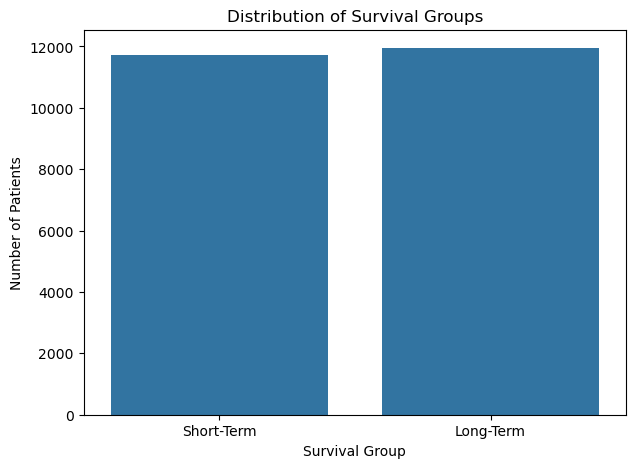

In [14]:
plt.figure(figsize=(7,5))

sns.countplot(
    data=df,
    x="Survival_Group"
)

plt.title("Distribution of Survival Groups")
plt.xlabel("Survival Group")
plt.ylabel("Number of Patients")

plt.show()

# Visualization 2 — Age

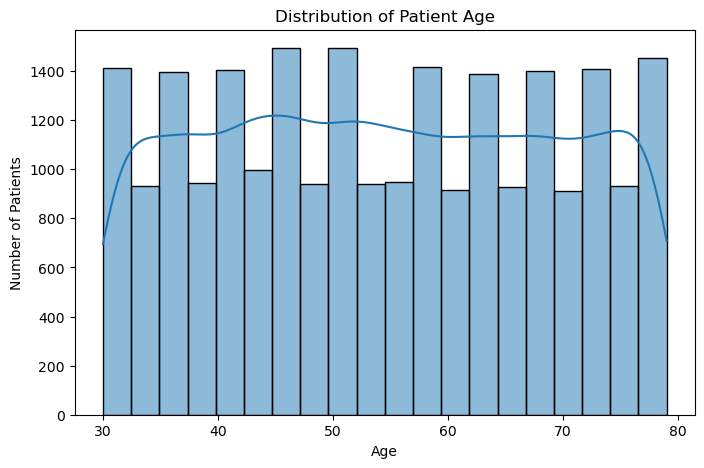

In [15]:
plt.figure(figsize=(8,5))

sns.histplot(
    data=df,
    x="Age",
    bins=20,
    kde=True
)

plt.title("Distribution of Patient Age")
plt.xlabel("Age")
plt.ylabel("Number of Patients")

plt.show()

# Visualization 3 — Tumor Size

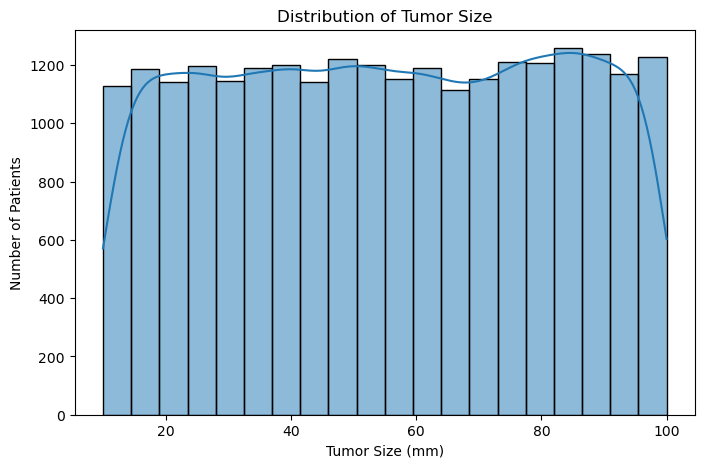

In [16]:
plt.figure(figsize=(8,5))

sns.histplot(
    data=df,
    x="Tumor_Size_mm",
    bins=20,
    kde=True
)

plt.title("Distribution of Tumor Size")
plt.xlabel("Tumor Size (mm)")
plt.ylabel("Number of Patients")

plt.show()

# Visualization 4 — Performance Status

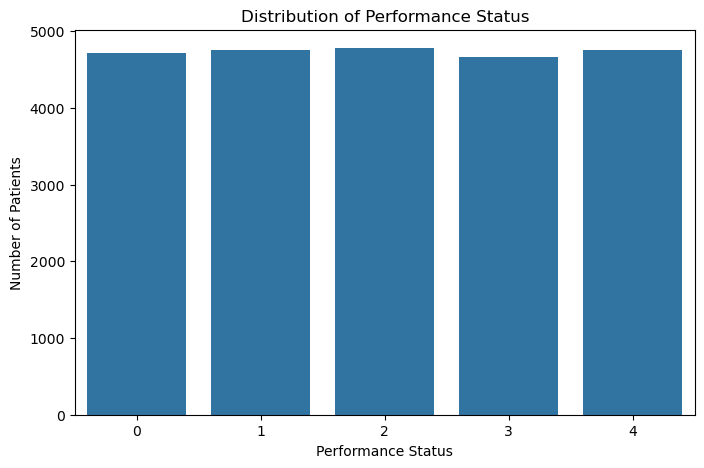

In [17]:
plt.figure(figsize=(8,5))

sns.countplot(
    data=df,
    x="Performance_Status"
)

plt.title("Distribution of Performance Status")
plt.xlabel("Performance Status")
plt.ylabel("Number of Patients")

plt.show()

# Bivariate Analysis: 
Bivariate analysis examines relationships between two variables.

# Visualization 5 — Age vs Survival

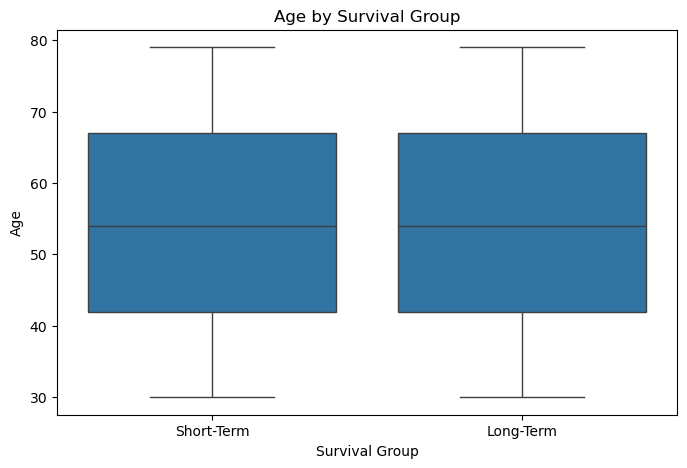

In [18]:
plt.figure(figsize=(8,5))

sns.boxplot(
    data=df,
    x="Survival_Group",
    y="Age"
)

plt.title("Age by Survival Group")
plt.xlabel("Survival Group")
plt.ylabel("Age")

plt.show()

# Visualization 6 — Tumor Size vs Survival

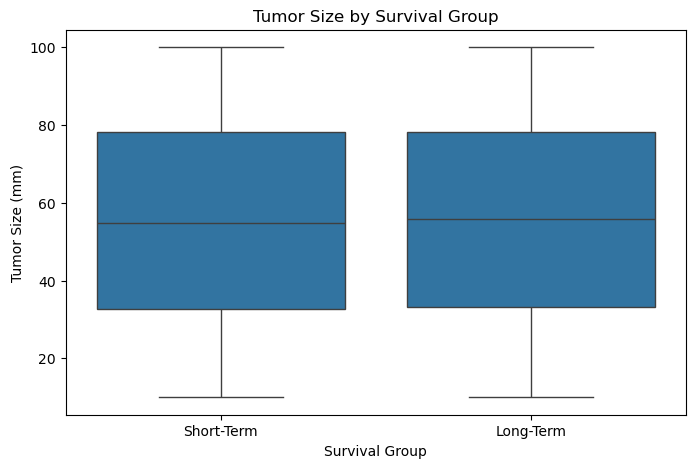

In [19]:
plt.figure(figsize=(8,5))

sns.boxplot(
    data=df,
    x="Survival_Group",
    y="Tumor_Size_mm"
)

plt.title("Tumor Size by Survival Group")
plt.xlabel("Survival Group")
plt.ylabel("Tumor Size (mm)")

plt.show()

# Visualization 7 — Performance Status vs Survival

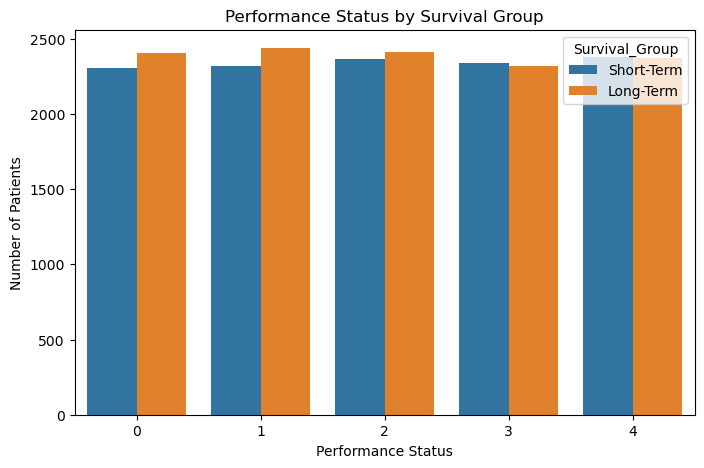

In [20]:
plt.figure(figsize=(8,5))

sns.countplot(
    data=df,
    x="Performance_Status",
    hue="Survival_Group"
)

plt.title("Performance Status by Survival Group")
plt.xlabel("Performance Status")
plt.ylabel("Number of Patients")

plt.show()

In [21]:
# Reconstruct categorical variables: Stage
def get_stage(row):
    if row["Stage_Stage II"] == 1:
        return "Stage II"
    elif row["Stage_Stage III"] == 1:
        return "Stage III"
    elif row["Stage_Stage IV"] == 1:
        return "Stage IV"
    else:
        return "Stage I"

df["Stage"] = df.apply(get_stage, axis=1)
print(df["Stage"].value_counts())

Stage
Stage IV     6011
Stage III    5922
Stage I      5905
Stage II     5820
Name: count, dtype: int64


# Visualization 8 — Stage vs Survival

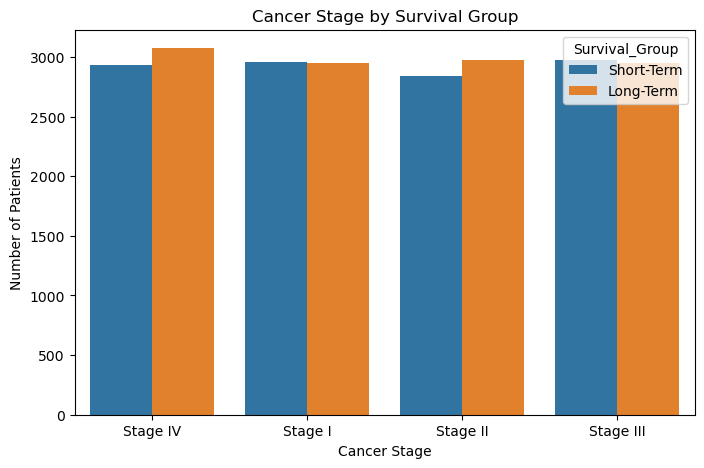

In [22]:
plt.figure(figsize=(8,5))

sns.countplot(
    data=df,
    x="Stage",
    hue="Survival_Group"
)

plt.title("Cancer Stage by Survival Group")
plt.xlabel("Cancer Stage")
plt.ylabel("Number of Patients")

plt.show()

The distribution of cancer stage was compared across the two survival groups to determine whether stage showed an observable difference in this dataset.

In [23]:
#Reconstruct categorical variables: Treatment
def get_treatment(row):
    if row["Treatment_Radiation Therapy"] == 1:
        return "Radiation Therapy"
    elif row["Treatment_Surgery"] == 1:
        return "Surgery"
    elif row["Treatment_Targeted Therapy"] == 1:
        return "Targeted Therapy"
    else:
        return "Other"

df["Treatment"] = df.apply(get_treatment, axis=1)
print(df["Treatment"].value_counts())

Treatment
Radiation Therapy    5966
Surgery              5944
Other                5936
Targeted Therapy     5812
Name: count, dtype: int64


# Visualization 9 — Treatment vs Survival

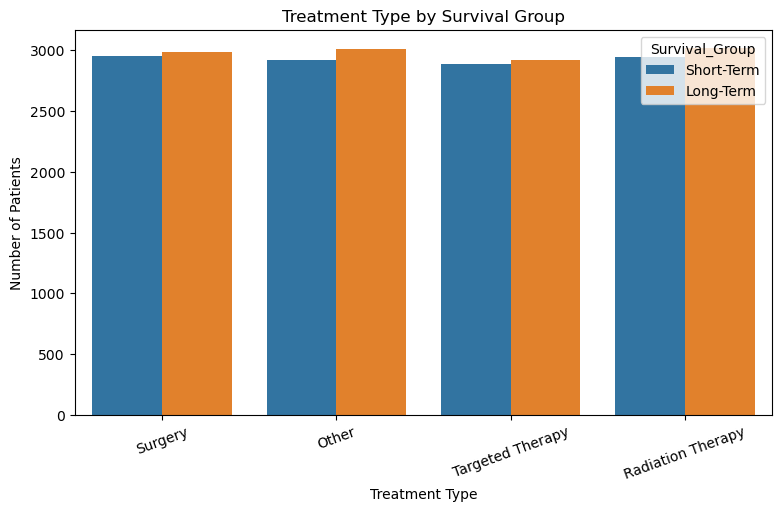

In [24]:
plt.figure(figsize=(9,5))

sns.countplot(
    data=df,
    x="Treatment",
    hue="Survival_Group"
)

plt.title("Treatment Type by Survival Group")
plt.xlabel("Treatment Type")
plt.ylabel("Number of Patients")

plt.xticks(rotation=20)

plt.show()

In [25]:
#Reconstruct categorical variables: Gender
df["Gender"] = np.where(
    df["Gender_Male"] == 1,
    "Male",
    "Female"
)
print(df["Gender"].value_counts())

Gender
Male      11924
Female    11734
Name: count, dtype: int64


# Visualization 10 — Gender vs Survival

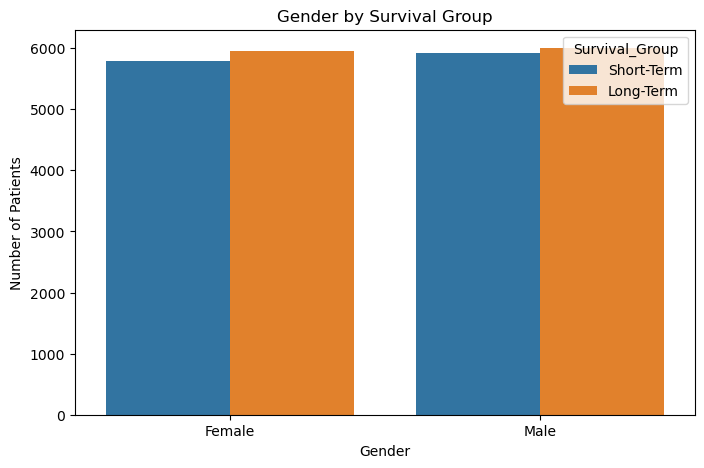

In [26]:
plt.figure(figsize=(8,5))

sns.countplot(
    data=df,
    x="Gender",
    hue="Survival_Group"
)

plt.title("Gender by Survival Group")
plt.xlabel("Gender")
plt.ylabel("Number of Patients")

plt.show()

In [27]:
#Reconstruct categorical variables: Smoking History
def get_smoking_history(row):
    if row["Smoking_History_Former Smoker"] == 1:
        return "Former Smoker"
    elif row["Smoking_History_Never Smoked"] == 1:
        return "Never Smoked"
    else:
        return "Current Smoker"

df["Smoking_History"] = df.apply(
    get_smoking_history,
    axis=1
)
print(df["Smoking_History"].value_counts())

Smoking_History
Former Smoker     7998
Current Smoker    7845
Never Smoked      7815
Name: count, dtype: int64


# Visualization 11 — Smoking History

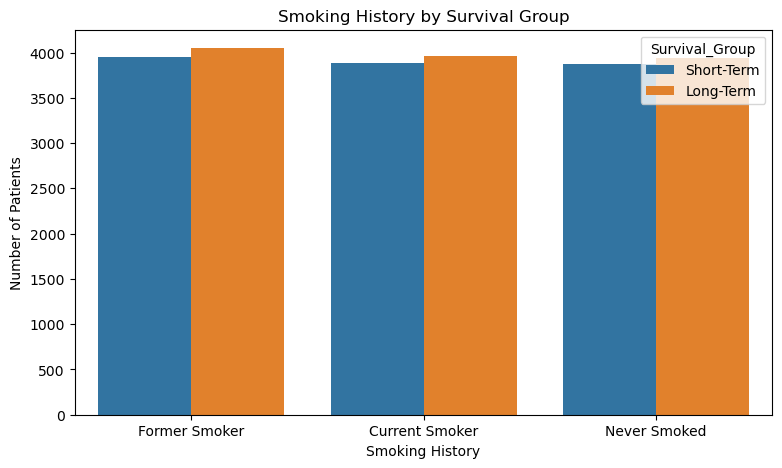

In [28]:
plt.figure(figsize=(9,5))

sns.countplot(
    data=df,
    x="Smoking_History",
    hue="Survival_Group"
)

plt.title("Smoking History by Survival Group")
plt.xlabel("Smoking History")
plt.ylabel("Number of Patients")

plt.show()

# Correlation Analysis

In [29]:
# Pearson
numeric_columns = df.select_dtypes(include=np.number).columns

pearson_corr = df[numeric_columns].corr(
    method="pearson"
)

display(pearson_corr)

,Age,Tumor_Size_mm,Performance_Status,Blood_Pressure_Systolic,Blood_Pressure_Diastolic,Blood_Pressure_Pulse,Hemoglobin_Level,White_Blood_Cell_Count,Platelet_Count,Albumin_Level,...,Insurance_Type_Other,Insurance_Type_Private,Family_History_Yes,Comorbidity_Diabetes_Yes,Comorbidity_Hypertension_Yes,Comorbidity_Heart_Disease_Yes,Comorbidity_Chronic_Lung_Disease_Yes,Comorbidity_Kidney_Disease_Yes,Comorbidity_Autoimmune_Disease_Yes,Comorbidity_Other_Yes
Age,1.000000,-0.007533,-0.001813,-0.002700,0.000967,0.002835,0.003116,0.004050,0.007802,0.000342,...,-0.015483,0.004246,-0.012956,-0.001849,0.001160,0.005016,-0.002316,0.007109,-0.005403,0.002148
Tumor_Size_mm,-0.007533,1.000000,0.006297,0.006060,-0.002182,0.009376,-0.003618,0.003213,0.003740,0.013113,...,0.006985,-0.010182,-0.010273,0.002746,0.003092,0.005215,0.004063,-0.000761,0.005848,-0.000486
Performance_Status,-0.001813,0.006297,1.000000,0.011411,0.004725,0.012159,-0.000093,-0.002090,0.007902,0.007774,...,0.009310,-0.000518,0.006100,-0.000657,-0.003050,-0.010585,-0.008313,-0.001076,-0.004007,0.007057
Blood_Pressure_Systolic,-0.002700,0.006060,0.011411,1.000000,-0.006421,-0.004962,-0.001355,0.000595,0.000213,0.013108,...,0.006084,-0.006447,0.006770,-0.002638,0.002966,0.006773,-0.002007,-0.015352,0.004179,0.001105
Blood_Pressure_Diastolic,0.000967,-0.002182,0.004725,-0.006421,1.000000,-0.006883,0.007291,-0.002113,-0.006269,-0.004882,...,-0.000583,-0.002204,0.002162,0.006416,0.006957,-0.004400,0.004208,0.003146,-0.008129,0.001512
Blood_Pressure_Pulse,0.002835,0.009376,0.012159,-0.004962,-0.006883,1.000000,-0.013985,-0.004052,-0.007221,-0.003241,...,0.008679,-0.009333,0.001827,-0.007697,-0.005611,0.001407,0.007074,-0.005706,0.006905,0.010913
Hemoglobin_Level,0.003116,-0.003618,-0.000093,-0.001355,0.007291,-0.013985,1.000000,-0.004095,0.005481,-0.006995,...,-0.001410,-0.006979,0.005648,0.000412,-0.006915,-0.002427,-0.000893,0.000032,0.003174,-0.009383
White_Blood_Cell_Count,0.004050,0.003213,-0.002090,0.000595,-0.002113,-0.004052,-0.004095,1.000000,0.002897,-0.006393,...,-0.004472,-0.001761,0.003123,0.002350,-0.009336,-0.005543,-0.006815,0.008327,0.001861,-0.014065
Platelet_Count,0.007802,0.003740,0.007902,0.000213,-0.006269,-0.007221,0.005481,0.002897,1.000000,-0.003410,...,-0.003303,-0.005866,-0.001013,-0.004617,0.001742,-0.001125,0.000996,0.004795,-0.000753,0.007298
Albumin_Level,0.000342,0.013113,0.007774,0.013108,-0.004882,-0.003241,-0.006995,-0.006393,-0.003410,1.000000,...,0.005550,0.004052,0.000539,0.007851,-0.003086,-0.016036,0.000567,0.003796,0.004940,-0.004673


In [30]:
# Spearman
spearman_corr = df[numeric_columns].corr(
    method="spearman"
)

display(spearman_corr)

,Age,Tumor_Size_mm,Performance_Status,Blood_Pressure_Systolic,Blood_Pressure_Diastolic,Blood_Pressure_Pulse,Hemoglobin_Level,White_Blood_Cell_Count,Platelet_Count,Albumin_Level,...,Insurance_Type_Other,Insurance_Type_Private,Family_History_Yes,Comorbidity_Diabetes_Yes,Comorbidity_Hypertension_Yes,Comorbidity_Heart_Disease_Yes,Comorbidity_Chronic_Lung_Disease_Yes,Comorbidity_Kidney_Disease_Yes,Comorbidity_Autoimmune_Disease_Yes,Comorbidity_Other_Yes
Age,1.000000,-0.007442,-0.001821,-0.002682,0.000992,0.002790,0.003031,0.003932,0.007827,0.000423,...,-0.015392,0.004256,-0.012990,-0.001809,0.001217,0.005064,-0.002335,0.007019,-0.005489,0.002135
Tumor_Size_mm,-0.007442,1.000000,0.006272,0.006003,-0.002230,0.009374,-0.003561,0.003192,0.003677,0.013140,...,0.006952,-0.010221,-0.010322,0.002668,0.003069,0.005145,0.004063,-0.000816,0.005910,-0.000414
Performance_Status,-0.001821,0.006272,1.000000,0.011399,0.004695,0.012147,-0.000075,-0.002131,0.007916,0.007798,...,0.009342,-0.000527,0.006100,-0.000675,-0.003035,-0.010593,-0.008306,-0.001074,-0.004017,0.007060
Blood_Pressure_Systolic,-0.002682,0.006003,0.011399,1.000000,-0.006342,-0.004933,-0.001317,0.000552,0.000237,0.013102,...,0.006113,-0.006453,0.006784,-0.002626,0.002954,0.006771,-0.002021,-0.015300,0.004176,0.001123
Blood_Pressure_Diastolic,0.000992,-0.002230,0.004695,-0.006342,1.000000,-0.006765,0.007289,-0.002054,-0.006313,-0.004903,...,-0.000568,-0.002191,0.002154,0.006426,0.006951,-0.004408,0.004212,0.003151,-0.008156,0.001515
Blood_Pressure_Pulse,0.002790,0.009374,0.012147,-0.004933,-0.006765,1.000000,-0.014029,-0.004097,-0.007241,-0.003250,...,0.008654,-0.009379,0.001818,-0.007664,-0.005620,0.001362,0.007043,-0.005709,0.006933,0.010869
Hemoglobin_Level,0.003031,-0.003561,-0.000075,-0.001317,0.007289,-0.014029,1.000000,-0.004074,0.005538,-0.006978,...,-0.001406,-0.007005,0.005639,0.000371,-0.006904,-0.002498,-0.000927,0.000083,0.003249,-0.009411
White_Blood_Cell_Count,0.003932,0.003192,-0.002131,0.000552,-0.002054,-0.004097,-0.004074,1.000000,0.002887,-0.006387,...,-0.004510,-0.001756,0.003150,0.002370,-0.009320,-0.005551,-0.006859,0.008294,0.001857,-0.014169
Platelet_Count,0.007827,0.003677,0.007916,0.000237,-0.006313,-0.007241,0.005538,0.002887,1.000000,-0.003392,...,-0.003296,-0.005846,-0.001129,-0.004642,0.001762,-0.001101,0.000976,0.004814,-0.000779,0.007320
Albumin_Level,0.000423,0.013140,0.007798,0.013102,-0.004903,-0.003250,-0.006978,-0.006387,-0.003392,1.000000,...,0.005582,0.004071,0.000554,0.007832,-0.003088,-0.016018,0.000572,0.003796,0.004930,-0.004717


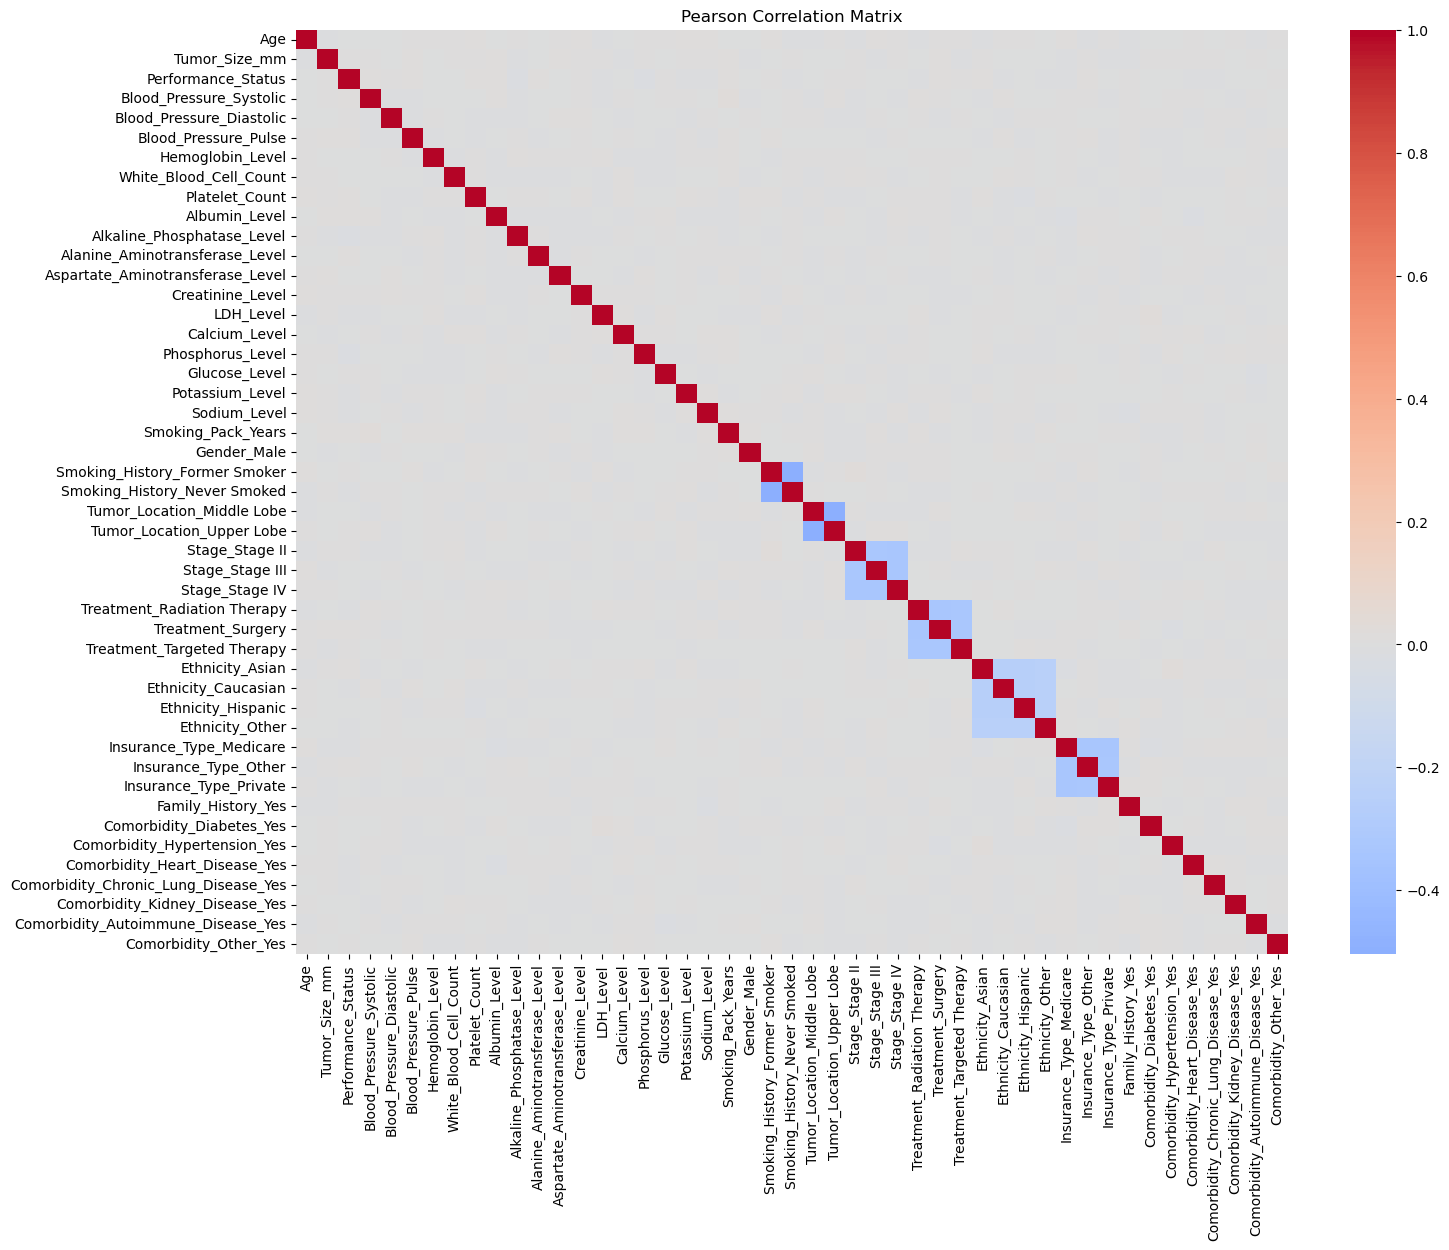

In [31]:
# Correlation heatmap
plt.figure(figsize=(16,12))

sns.heatmap(
    pearson_corr,
    cmap="coolwarm",
    center=0
)

plt.title("Pearson Correlation Matrix")
plt.show()

In [32]:
#Find strongest correlations
corr_pairs = (
    pearson_corr
    .where(
        np.triu(
            np.ones(pearson_corr.shape),
            k=1
        ).astype(bool)
    )
    .stack()
    .sort_values(
        key=abs,
        ascending=False
    )
)

display(corr_pairs.head(15))

Tumor_Location_Middle Lobe     Tumor_Location_Upper Lobe      -0.503145
Smoking_History_Former Smoker  Smoking_History_Never Smoked   -0.501927
Stage_Stage III                Stage_Stage IV                 -0.337244
Treatment_Radiation Therapy    Treatment_Surgery              -0.336383
Insurance_Type_Medicare        Insurance_Type_Private         -0.334573
Stage_Stage II                 Stage_Stage IV                 -0.333370
Insurance_Type_Medicare        Insurance_Type_Other           -0.333101
Insurance_Type_Other           Insurance_Type_Private         -0.331606
Treatment_Radiation Therapy    Treatment_Targeted Therapy     -0.331395
Treatment_Surgery              Treatment_Targeted Therapy     -0.330578
Stage_Stage II                 Stage_Stage III                -0.330061
Ethnicity_Caucasian            Ethnicity_Hispanic             -0.252077
Ethnicity_Asian                Ethnicity_Caucasian            -0.251182
                               Ethnicity_Hispanic             -0

In [33]:
#Find high correlations
high_corr = corr_pairs[
    abs(corr_pairs) >= 0.70
]

display(high_corr)

Series([], dtype: float64)

The correlation analysis did not identify many highly correlated predictor pairs above the selected threshold. This suggests that severe multicollinearity may not be widespread among the numerical variables.


In [34]:
#Correlation with the target
target_numeric = (
    df["Survival_Group"] == "Long-Term"
).astype(int)

In [35]:
target_correlations = (
    df[numeric_columns]
    .corrwith(target_numeric)
    .sort_values(
        key=abs,
        ascending=False
    )
)

display(target_correlations)

Comorbidity_Chronic_Lung_Disease_Yes    0.012808
Blood_Pressure_Pulse                   -0.012763
Albumin_Level                          -0.011780
Ethnicity_Hispanic                      0.011503
Ethnicity_Caucasian                    -0.010639
Performance_Status                     -0.010525
White_Blood_Cell_Count                  0.010479
Tumor_Location_Middle Lobe             -0.009997
Tumor_Size_mm                           0.009568
Comorbidity_Diabetes_Yes                0.009242
Stage_Stage III                        -0.008350
Ethnicity_Other                         0.008089
Stage_Stage IV                          0.007625
Stage_Stage II                          0.007209
Aspartate_Aminotransferase_Level       -0.007145
LDH_Level                              -0.006386
Comorbidity_Kidney_Disease_Yes          0.006347
Comorbidity_Hypertension_Yes           -0.006314
Phosphorus_Level                        0.005924
Blood_Pressure_Diastolic                0.005799
Glucose_Level       

# Business / Healthcare Insights

# Insight 1 — Balanced target

The survival outcome is relatively balanced, with 11,948 Long-Term and 11,710 Short-Term patients. This indicates that the dataset does not have a severe class-imbalance problem, which should make standard classification metrics more meaningful during the modeling stage.

# Insight 2 — Age

The age distributions of the Short-Term and Long-Term groups are very similar. The mean age is approximately 54.5 years for Long-Term patients and 54.4 years for Short-Term patients. This suggests that age alone may have limited discriminatory power in this dataset.

# Insight 3 — Tumor size

Tumor size also shows only a small difference between the survival groups. The average tumor size is approximately 55.6 mm among Long-Term patients and 55.1 mm among Short-Term patients. Therefore, tumor size alone does not appear to strongly separate the two outcome groups.

# Insight 4 — Stage

The distributions of cancer stage are relatively similar across the two survival groups. This indicates that stage, as represented in this dataset, does not produce a strong visual separation between the outcomes.

# Insight 5 — Correlation

Pearson correlation analysis found only weak individual relationships between the numerical predictors and survival outcome. This suggests that survival classification may depend more on combinations or nonlinear relationships among predictors than on one dominant numerical variable.

# Feature Engineering

# 1. Age Group 
Age groups make it easier to investigate whether survival patterns differ across broad age categories.

In [36]:
df["Age_Group"] = pd.cut(
    df["Age"],
    bins=[29, 49, 64, 79],
    labels=[
        "30-49",
        "50-64",
        "65-79"
    ]
)

# 2. Tumor Size Group
Tumor size ranges approximately from 10 to 100 mm.. Categorizing tumor size can make group-level comparisons easier and may allow a model to capture nonlinear effects.

In [37]:
df["Tumor_Size_Group"] = pd.cut(
    df["Tumor_Size_mm"],
    bins=[0, 40, 70, np.inf],
    labels=[
        "Small",
        "Medium",
        "Large"
    ]
)

# 3. Comorbidity Count
Instead of considering each comorbidity separately, this creates an overall measure of comorbidity burden.

In [38]:
comorbidity_columns = [
    "Comorbidity_Diabetes_Yes",
    "Comorbidity_Hypertension_Yes",
    "Comorbidity_Heart_Disease_Yes",
    "Comorbidity_Chronic_Lung_Disease_Yes",
    "Comorbidity_Kidney_Disease_Yes",
    "Comorbidity_Autoimmune_Disease_Yes",
    "Comorbidity_Other_Yes"
]

df["Comorbidity_Count"] = (
    df[comorbidity_columns]
    .sum(axis=1)
)

# 4. Treatment Count
This represents how many recorded treatment modalities are present for each patient.

In [39]:
treatment_columns = [
    "Treatment_Radiation Therapy",
    "Treatment_Surgery",
    "Treatment_Targeted Therapy"
]

df["Treatment_Count"] = (
    df[treatment_columns]
    .sum(axis=1)
)

# 5. Blood Pressure Difference
The difference between systolic and diastolic pressure provides a derived cardiovascular measure that is not directly represented by either measurement alone.

In [40]:
df["Blood_Pressure_Difference"] = (
    df["Blood_Pressure_Systolic"]
    -
    df["Blood_Pressure_Diastolic"]
)

These engineered features were created because they may provide additional information or more interpretable representations of existing variables. Their actual usefulness for prediction should be evaluated during the modeling stage.

In [62]:
df.to_csv("../data/cleaned_dataset_assignment3.csv", index=False)

print("Updated dataset saved successfully.")
print("Dataset shape:", df.shape)

Updated dataset saved successfully.
Dataset shape: (23658, 57)


# Evaluate the engineered features

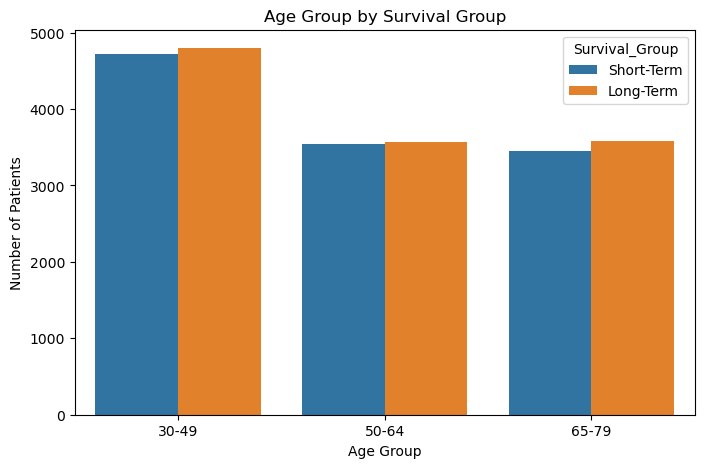

In [41]:
# Age Group vs Survival
plt.figure(figsize=(8,5))

sns.countplot(
    data=df,
    x="Age_Group",
    hue="Survival_Group"
)

plt.title("Age Group by Survival Group")
plt.xlabel("Age Group")
plt.ylabel("Number of Patients")

plt.show()

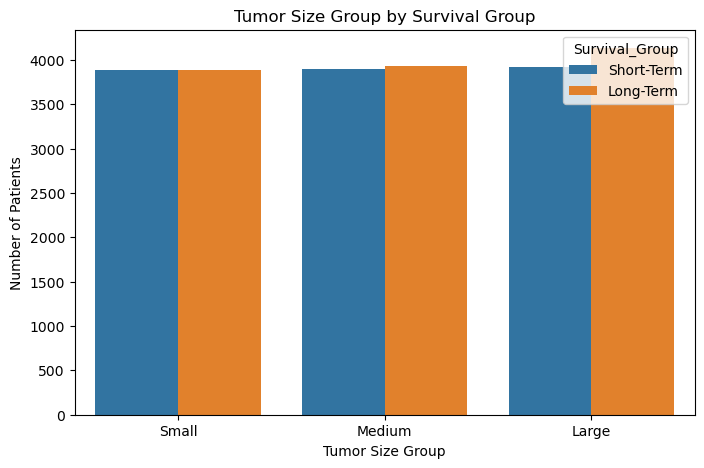

In [42]:
# Tumor Size Group vs Survival
plt.figure(figsize=(8,5))

sns.countplot(
    data=df,
    x="Tumor_Size_Group",
    hue="Survival_Group"
)

plt.title("Tumor Size Group by Survival Group")
plt.xlabel("Tumor Size Group")
plt.ylabel("Number of Patients")

plt.show()

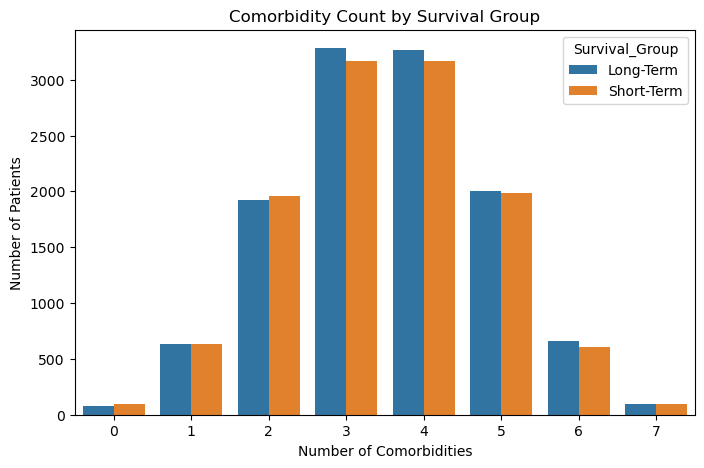

In [43]:
# Comorbidity Count vs Survival
plt.figure(figsize=(8,5))

sns.countplot(
    data=df,
    x="Comorbidity_Count",
    hue="Survival_Group"
)

plt.title("Comorbidity Count by Survival Group")
plt.xlabel("Number of Comorbidities")
plt.ylabel("Number of Patients")

plt.show()

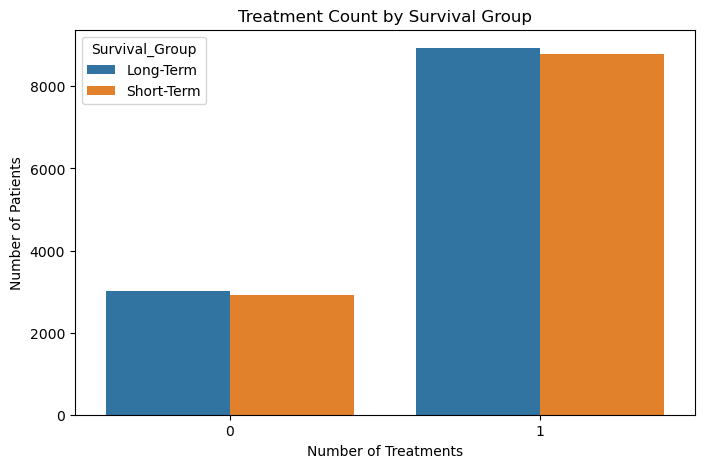

In [44]:
# Treatment Count vs Survival
plt.figure(figsize=(8,5))

sns.countplot(
    data=df,
    x="Treatment_Count",
    hue="Survival_Group"
)

plt.title("Treatment Count by Survival Group")
plt.xlabel("Number of Treatments")
plt.ylabel("Number of Patients")

plt.show()

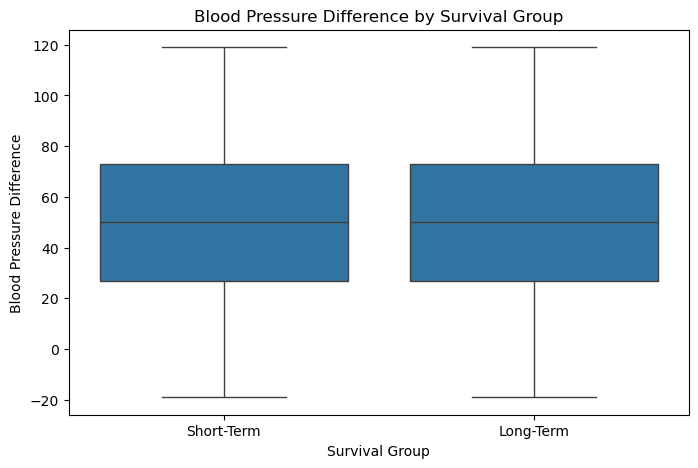

In [45]:
# Blood Pressure Difference vs Survival
plt.figure(figsize=(8,5))

sns.boxplot(
    data=df,
    x="Survival_Group",
    y="Blood_Pressure_Difference"
)

plt.title("Blood Pressure Difference by Survival Group")
plt.xlabel("Survival Group")
plt.ylabel("Blood Pressure Difference")

plt.show()

# Variance Threshold

In [46]:
pca_features = [
    col for col in df.columns
    if col not in [
        "Survival_Group",
        "Age_Group",
        "Tumor_Size_Group",
        "Stage",
        "Treatment",
        "Gender",
        "Smoking_History"
    ]
]

X_pca = df[pca_features].copy()

print("Number of predictors:", X_pca.shape[1])

Number of predictors: 50


In [47]:
from sklearn.feature_selection import VarianceThreshold

selector = VarianceThreshold(threshold=0.01)

X_variance = selector.fit_transform(X_pca)

print("Original number of features:", X_pca.shape[1])
print("Features after variance filtering:", X_variance.shape[1])

Original number of features: 50
Features after variance filtering: 50


The variance threshold analysis did not remove a substantial number of predictors, indicating that the selected numerical features contained sufficient variation for further analysis.

# PCA

In [48]:
# Separate X and y
X = df[pca_features]
y = df["Survival_Group"]

In [49]:
# Standardize
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

In [50]:
# Run PCA
from sklearn.decomposition import PCA

pca = PCA()

X_pca = pca.fit_transform(X_scaled)

In [51]:
# Explained variance
explained_variance = pca.explained_variance_ratio_

cumulative_variance = np.cumsum(explained_variance)

pca_summary = pd.DataFrame({
    "Component": range(1, len(explained_variance) + 1),
    "Explained_Variance": explained_variance,
    "Cumulative_Variance": cumulative_variance
})

display(pca_summary)

,Component,Explained_Variance,Cumulative_Variance
0,1,4.031937e-02,0.040319
1,2,3.995049e-02,0.080270
2,3,3.031276e-02,0.110583
3,4,3.013590e-02,0.140719
4,5,2.731004e-02,0.168029
5,6,2.716778e-02,0.195196
6,7,2.692973e-02,0.222126
7,8,2.680381e-02,0.248930
8,9,2.657601e-02,0.275506
9,10,2.650533e-02,0.302011


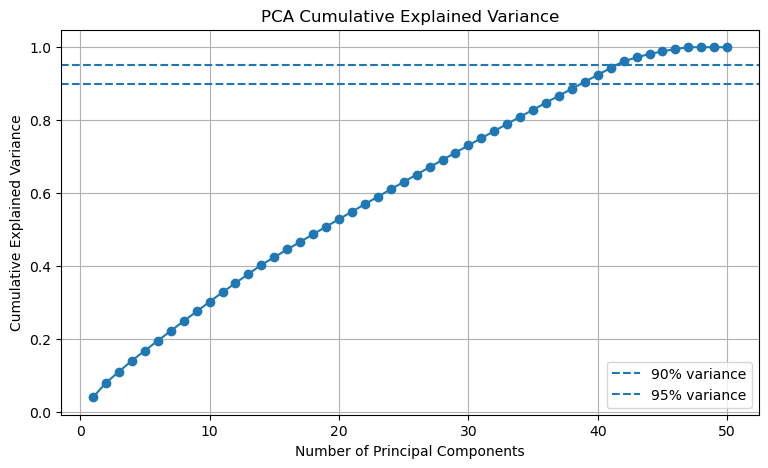

In [52]:
# Make the PCA graph
plt.figure(figsize=(9,5))

plt.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance,
    marker="o"
)

plt.axhline(
    y=0.90,
    linestyle="--",
    label="90% variance"
)

plt.axhline(
    y=0.95,
    linestyle="--",
    label="95% variance"
)

plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("PCA Cumulative Explained Variance")

plt.legend()
plt.grid()

plt.show()

In [53]:
# Find the number of components
components_90 = np.argmax(
    cumulative_variance >= 0.90
) + 1

components_95 = np.argmax(
    cumulative_variance >= 0.95
) + 1

print(
    "Components needed for 90% variance:",
    components_90
)

print(
    "Components needed for 95% variance:",
    components_95
)

Components needed for 90% variance: 39
Components needed for 95% variance: 42


# Comment
The original dataset contained 50 predictors. PCA required 39 principal components to retain 90% of the total variance and 42 components to retain 95%. Therefore, PCA provided some dimensionality reduction, although a relatively large number of components was still required.


# Compare Original vs PCA

In [54]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [55]:
# Original features
scaler_original = StandardScaler()

X_train_scaled = scaler_original.fit_transform(X_train)
X_test_scaled = scaler_original.transform(X_test)

model_original = LogisticRegression(
    max_iter=1000
)

model_original.fit(
    X_train_scaled,
    y_train
)

pred_original = model_original.predict(X_test_scaled)

accuracy_original = accuracy_score(
    y_test,
    pred_original
)

print(
    "Original feature accuracy:",
    accuracy_original
)

Original feature accuracy: 0.4978867286559594


In [58]:
# PCA features
pca_model = PCA(
    n_components=0.90
) 

X_train_pca = pca_model.fit_transform(
    X_train_scaled
)

X_test_pca = pca_model.transform(
    X_test_scaled
)

model_pca = LogisticRegression(
    max_iter=1000
)

model_pca.fit(
    X_train_pca,
    y_train
)

pred_pca = model_pca.predict(X_test_pca)

accuracy_pca = accuracy_score(
    y_test,
    pred_pca
)

print(
    "PCA feature accuracy:",
    accuracy_pca
)

PCA feature accuracy: 0.49640743871513104


In [60]:
# Comparison
comparison = pd.DataFrame({
    "Model": ["Original Features", "PCA Features"],
    "Number of Features": [X_train.shape[1], pca_model.n_components_],
    "Accuracy": [accuracy_original, accuracy_pca]
})

print(comparison)

               Model  Number of Features  Accuracy
0  Original Features                  50  0.497887
1       PCA Features                  39  0.496407


#PCA reduced the number of model inputs from 50 to 39, a 22% reduction, while producing almost the same accuracy.

# Reflection on How EDA Influenced Modeling Decisions
EDA helped me understand which variables and patterns may be useful for predicting survival. The visualizations and correlation analysis showed that individual variables did not have strong relationships with survival, so future models may need to consider multiple features together.

EDA also guided my feature engineering. I created five new features: Age_Group, Tumor_Size_Group, Comorbidity_Count, Treatment_Count, and Blood_Pressure_Difference, and evaluated them using visualizations.

I also explored feature selection and PCA. PCA reduced the number of features from 50 to 39 while retaining 90% of the variance. The Logistic Regression results were very similar for the original and PCA features (49.79% vs. 49.64%). This showed that PCA can reduce the number of features, but it also reduces interpretability.

Overall, EDA helped me make more informed decisions about feature engineering, feature selection, and dimensionality reduction before moving on to future modeling.

# Conclusion 
Overall, the EDA helped me better understand the dataset and identify patterns related to patient survival. The visualizations, correlation analysis, and business insights showed that survival is not strongly explained by one variable alone. The engineered features provided additional ways to look at the data, while PCA showed that the number of features could be reduced from 50 to 39 while keeping 90% of the variance. The comparison with Logistic Regression showed very similar accuracy between the original and PCA features. Overall, this analysis gave me a better understanding of the data and provided a foundation for future modeling.